In [1]:
import itertools
import numpy as np
import pandas as pd
import glob, os
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D                             

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
# load the files

files = sorted(f for f in glob.glob("*.csv")
               if f.startswith(("bi-encoder_", "colbert_", "cross-encoder_")))
print(len(files), "files found")


score_tables = {}

# store scores in dict
for file_name in files:
    score_frame = (pd.read_csv(file_name)
                     .filter(like="_score")
                     .drop(columns=["max_score", "median_score"]))
    score_tables[file_name] = score_frame.values
    print(file_name, score_tables[file_name].shape)
    
    
# score_tables

14 files found
bi-encoder_BAAI-bge-large-en-v1.5.csv (100, 14)
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv (100, 14)
bi-encoder_Qwen-Qwen3-Embedding-4B.csv (100, 14)
bi-encoder_Qwen-Qwen3-Embedding-8B.csv (100, 14)
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv (100, 14)
colbert_LiquidAI-LFM2-ColBERT-350M.csv (100, 14)
colbert_colbert-ir-colbertv2.0.csv (100, 14)
colbert_lightonai-Reason-ModernColBERT.csv (100, 14)
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv (100, 14)
cross-encoder_BAAI-bge-reranker-v2-m3.csv (100, 14)
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv (100, 14)
cross-encoder_Qwen-Qwen3-Reranker-4B.csv (100, 14)
cross-encoder_Qwen-Qwen3-Reranker-8B.csv (100, 14)
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv (100, 14)


In [3]:
def average_cutoffs(scores, k_values, number_of_specialists, show=True):
    average_cutoff_for_k = []

    for k in k_values:
        cutoffs_for_this_k = []
        for chosen_columns in itertools.combinations(range(number_of_specialists), k):
#             print(chosen_columns)
            chosen_scores = scores[:, list(chosen_columns)]
#             print(chosen_scores[:1])
            gap = chosen_scores.max(axis=1) - np.median(chosen_scores, axis=1)
#             print(gap[:1])
            cutoffs_for_this_k.append(np.percentile(gap, 90))
#             break                      # stop after the first pool
        average_cutoff_for_k.append(np.mean(cutoffs_for_this_k))
        if show:
            print(f"k={k}: {len(cutoffs_for_this_k)} pools, average cutoff = {average_cutoff_for_k[-1]:.5f}")
    return average_cutoff_for_k

In [4]:
# ks = [3, 5, 8, 10, 12, 14]
ks = [3, 4, 5, 6, 7, 8, 10, 12, 14]


real_rows = {}
for model in files:
    scores = score_tables[model]
#     print(scores[:3])
    real_rows[model] = average_cutoffs(scores, ks, number_of_specialists=14,show=False)
    print("done:", model)

real_table = pd.DataFrame(real_rows, index=ks).T
real_table.columns.name = "K"
display(real_table.round(5))

done: bi-encoder_BAAI-bge-large-en-v1.5.csv
done: bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv
done: bi-encoder_Qwen-Qwen3-Embedding-4B.csv
done: bi-encoder_Qwen-Qwen3-Embedding-8B.csv
done: bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv
done: colbert_LiquidAI-LFM2-ColBERT-350M.csv
done: colbert_colbert-ir-colbertv2.0.csv
done: colbert_lightonai-Reason-ModernColBERT.csv
done: colbert_mixedbread-ai-mxbai-colbert-large-v1.csv
done: cross-encoder_BAAI-bge-reranker-v2-m3.csv
done: cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv
done: cross-encoder_Qwen-Qwen3-Reranker-4B.csv
done: cross-encoder_Qwen-Qwen3-Reranker-8B.csv
done: cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv


K,3,4,5,6,7,8,10,12,14
bi-encoder_BAAI-bge-large-en-v1.5.csv,0.07002,0.07586,0.08460,0.08787,0.09230,0.09430,0.09885,0.10221,0.10527
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,0.10010,0.10698,0.11746,0.12064,0.12717,0.12926,0.13493,0.13912,0.14130
bi-encoder_Qwen-Qwen3-Embedding-4B.csv,0.08474,0.09245,0.10428,0.10885,0.11692,0.12034,0.12928,0.13686,0.14426
bi-encoder_Qwen-Qwen3-Embedding-8B.csv,0.08042,0.08792,0.09865,0.10213,0.10847,0.11060,0.11589,0.11938,0.11952
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,0.10079,0.10879,0.12133,0.12584,0.13272,0.13595,0.14380,0.15100,0.15580
colbert_LiquidAI-LFM2-ColBERT-350M.csv,0.00118,0.00133,0.00152,0.00162,0.00175,0.00183,0.00200,0.00212,0.00222
colbert_colbert-ir-colbertv2.0.csv,0.06720,0.07420,0.08356,0.08882,0.09495,0.09982,0.10804,0.11413,0.12113
colbert_lightonai-Reason-ModernColBERT.csv,0.02560,0.02867,0.03280,0.03476,0.03741,0.03952,0.04365,0.04683,0.04935
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,0.10459,0.11051,0.12173,0.12538,0.13017,0.13287,0.13776,0.14123,0.14436
cross-encoder_BAAI-bge-reranker-v2-m3.csv,0.00005,0.00006,0.00008,0.00009,0.00010,0.00011,0.00012,0.00013,0.00014


In [5]:
def fit_log(k, y):
    c1, c0 = np.polyfit(np.log(k), y, 1)   # y = c0 + c1*ln(k)
    return c0, c1

def predict_log(c0, c1, k):
    return c0 + c1 * np.log(k)

In [6]:
# train_k = [3, 5, 8, 10]

train_k = np.array([3,4,5,6,7,8])
test_k  = np.array([10, 12, 14])
all_k   = np.concatenate([train_k, test_k])


rows = []
for model, row in real_table.iterrows():

    c0, c1 = fit_log(train_k, row[train_k].values)
    
    for k in all_k:
        pred = predict_log(c0, c1, k)
        act  = row[k]
        rows.append({"model": model, "k": k,
                     "split": "train" if k in train_k else "test",
                     "c0": c0, "c1": c1,
                     "actual_p90": act,
                     "log_pred": pred,
                     "error": pred - act,
                     "abs_%_error": 100 * abs(pred - act) / act})

comparison = pd.DataFrame(rows)
display(comparison.round(5))

,model,k,split,c0,c1,actual_p90,log_pred,error,abs_%_error
0,bi-encoder_BAAI-bge-large-en-v1.5.csv,3,train,0.04144,0.02586,0.07002,0.06985,-0.00017,0.24137
1,bi-encoder_BAAI-bge-large-en-v1.5.csv,4,train,0.04144,0.02586,0.07586,0.07729,0.00143,1.88593
2,bi-encoder_BAAI-bge-large-en-v1.5.csv,5,train,0.04144,0.02586,0.08460,0.08306,-0.00155,1.82637
3,bi-encoder_BAAI-bge-large-en-v1.5.csv,6,train,0.04144,0.02586,0.08787,0.08777,-0.00010,0.11046
4,bi-encoder_BAAI-bge-large-en-v1.5.csv,7,train,0.04144,0.02586,0.09230,0.09176,-0.00054,0.58184
5,bi-encoder_BAAI-bge-large-en-v1.5.csv,8,train,0.04144,0.02586,0.09430,0.09521,0.00092,0.97316
6,bi-encoder_BAAI-bge-large-en-v1.5.csv,10,test,0.04144,0.02586,0.09885,0.10098,0.00214,2.16344
7,bi-encoder_BAAI-bge-large-en-v1.5.csv,12,test,0.04144,0.02586,0.10221,0.10570,0.00349,3.41083
8,bi-encoder_BAAI-bge-large-en-v1.5.csv,14,test,0.04144,0.02586,0.10527,0.10969,0.00441,4.18990
9,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,3,train,0.06560,0.03107,0.10010,0.09974,-0.00036,0.35655


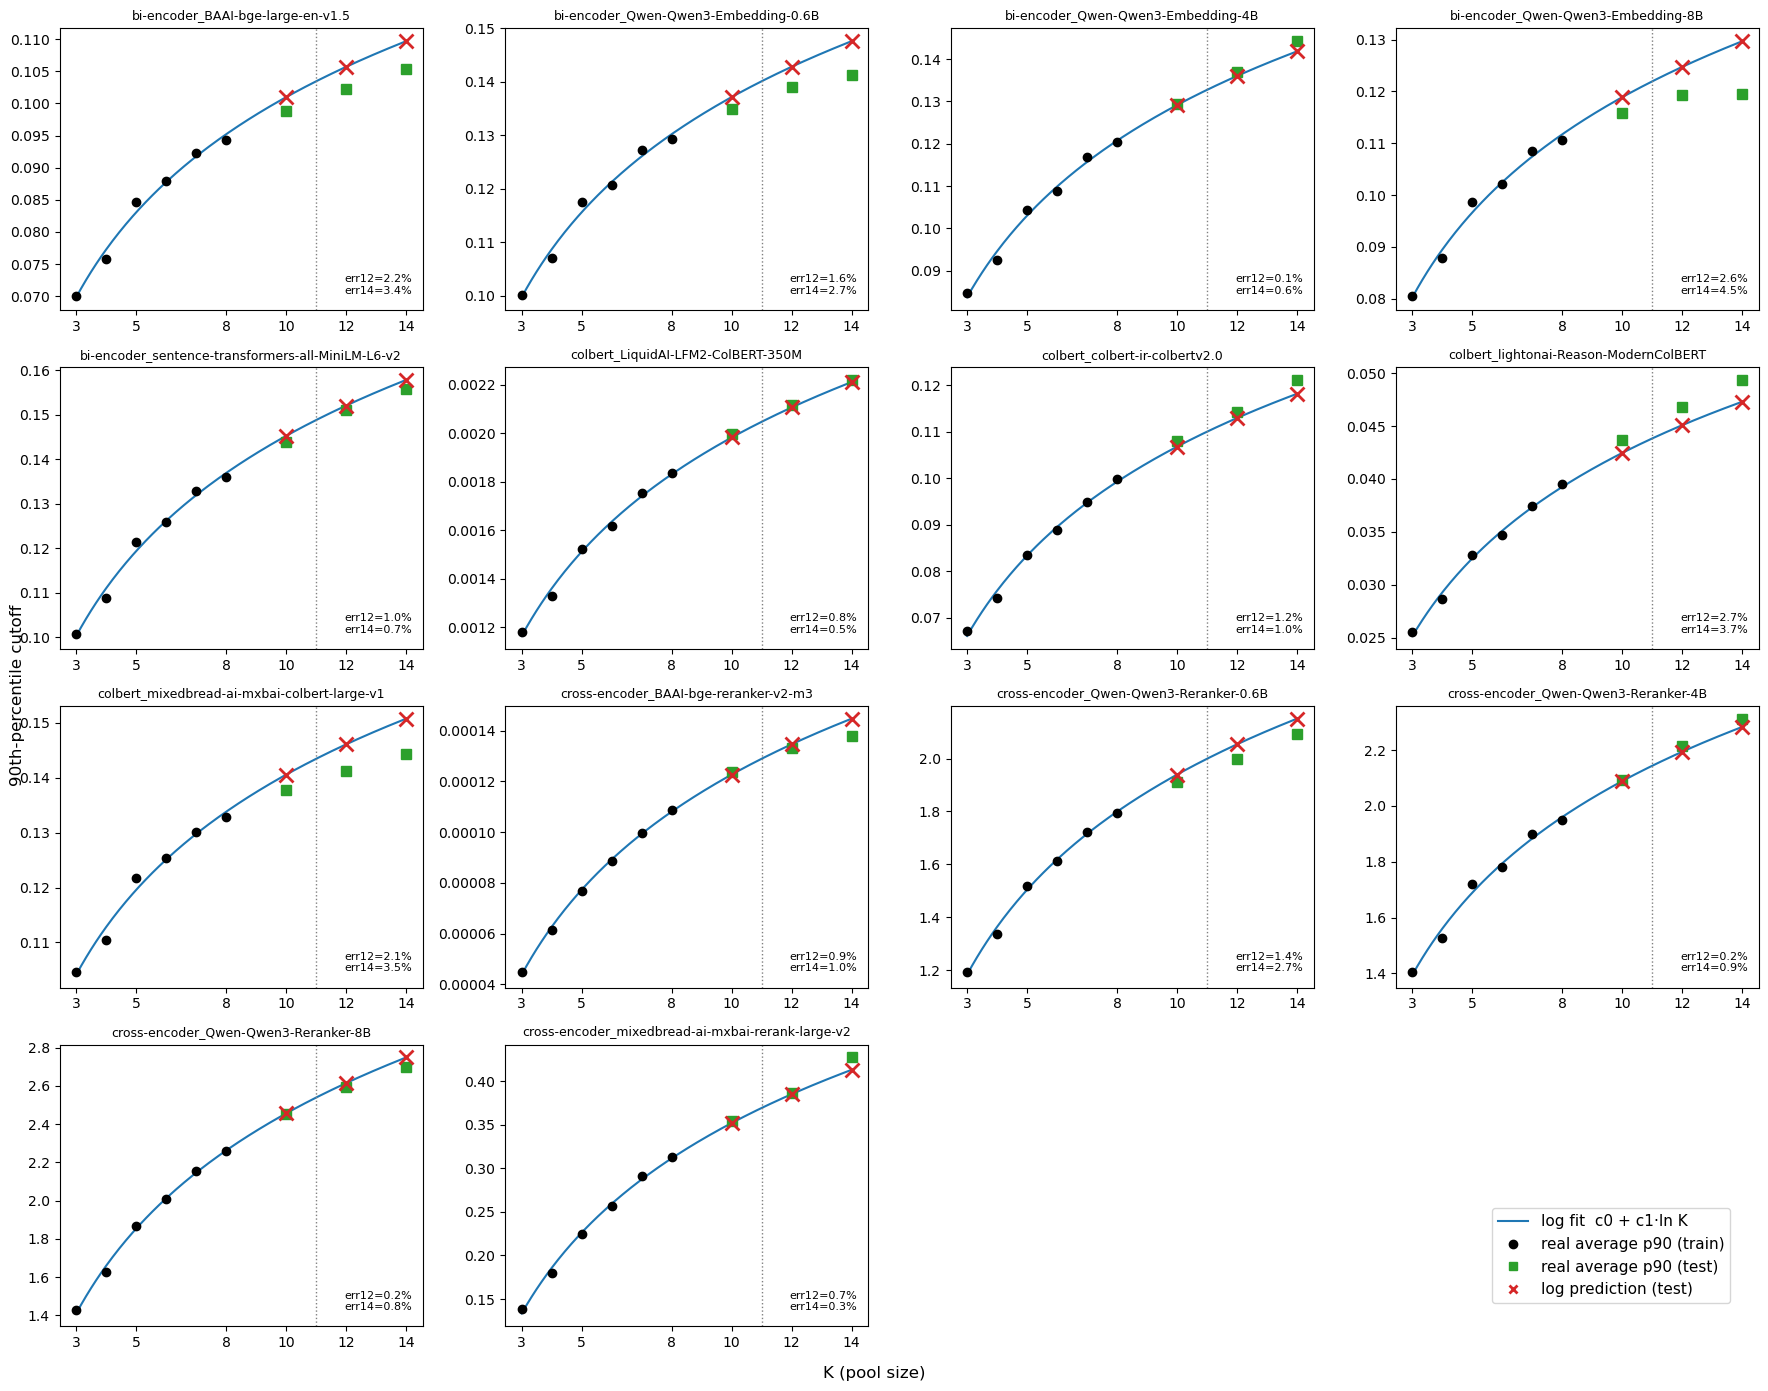

In [7]:
models = comparison["model"].unique()
k_curve = np.linspace(3, 14, 200)

fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, model in zip(axes.flat, models):
    d = comparison[comparison["model"] == model]
    train = d[d["split"] == "train"]
    test  = d[d["split"] == "test"]
    c0, c1 = d["c0"].iloc[0], d["c1"].iloc[0]

    # fitted curve
    ax.plot(k_curve, predict_log(c0, c1, k_curve), color="tab:blue", lw=1.5)
    # real averages
    ax.plot(train["k"], train["actual_p90"], "o", color="black")
    ax.plot(test["k"],  test["actual_p90"],  "s", color="tab:green", ms=7)
    # predictions at 12, 14
    ax.plot(test["k"],  test["log_pred"],    "x", color="tab:red", ms=10, mew=2)

    ax.axvline(11, color="grey", ls=":", lw=1)           # train | test split
    ax.set_title(model.replace(".csv", ""), fontsize=9)
    ax.set_xticks([3, 5, 8, 10, 12, 14])
    ax.text(0.97, 0.05,
            f"err12={test['abs_%_error'].iloc[0]:.1f}%\nerr14={test['abs_%_error'].iloc[1]:.1f}%",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=8)

for ax in axes.flat[len(models):]:
    ax.axis("off")

fig.legend(handles=[
    Line2D([], [], color="tab:blue", label="log fit  c0 + c1·ln K"),
    Line2D([], [], marker="o", ls="", color="black", label="real average p90 (train)"),
    Line2D([], [], marker="s", ls="", color="tab:green", label="real average p90 (test)"),
    Line2D([], [], marker="x", ls="", color="tab:red", mew=2, label="log prediction (test)"),
], loc="lower right", bbox_to_anchor=(0.98, 0.06), fontsize=11)

fig.supxlabel("K (pool size)")
fig.supylabel("90th-percentile cutoff")
plt.tight_layout()
plt.show()

In [8]:
constants = comparison.groupby("model")[["c0", "c1"]].first()
display(constants.round(5))

,c0,c1
model,,
bi-encoder_BAAI-bge-large-en-v1.5.csv,0.04144,0.02586
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,0.06560,0.03107
bi-encoder_Qwen-Qwen3-Embedding-4B.csv,0.04226,0.03773
bi-encoder_Qwen-Qwen3-Embedding-8B.csv,0.04501,0.03210
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,0.05919,0.03736
colbert_LiquidAI-LFM2-ColBERT-350M.csv,0.00042,0.00068
colbert_colbert-ir-colbertv2.0.csv,0.02888,0.03383
colbert_lightonai-Reason-ModernColBERT.csv,0.00940,0.01436
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,0.07083,0.03029


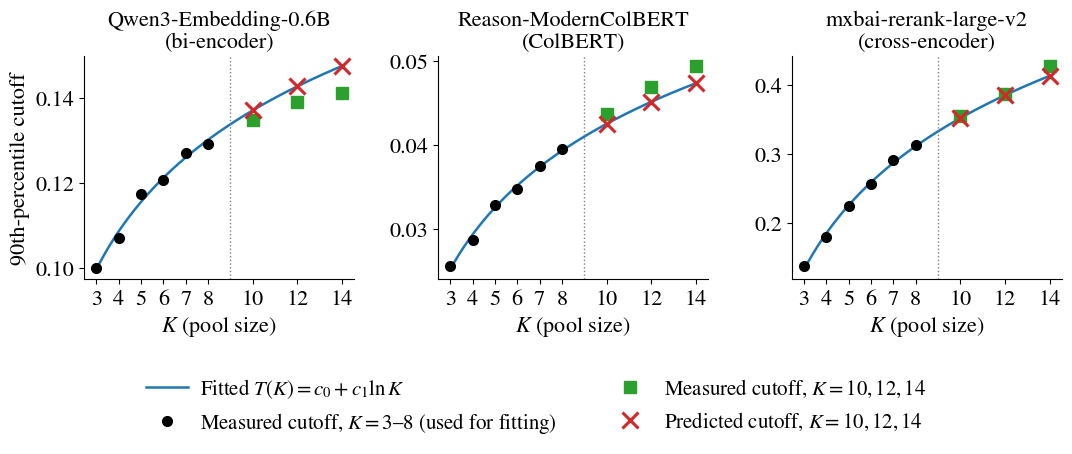

In [36]:
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 16, "axes.titlesize": 16, "axes.labelsize": 16,
                     "xtick.labelsize": 16, "ytick.labelsize": 16, "legend.fontsize": 15})
selected = {
    "bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv":              "Qwen3-Embedding-0.6B (bi-encoder)",
    "colbert_lightonai-Reason-ModernColBERT.csv":            "Reason-ModernColBERT (ColBERT)",
    "cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv": "mxbai-rerank-large-v2 (cross-encoder)",
}

k_curve = np.linspace(3, 14, 200)
fig, axes = plt.subplots(1, 3, figsize=(11, 4.6))                                       

for ax, (model, title) in zip(axes, selected.items()):
    d = comparison[comparison["model"] == model]
    train = d[d["split"] == "train"]
    test  = d[d["split"] == "test"]
    c0, c1 = d["c0"].iloc[0], d["c1"].iloc[0]

    ax.plot(k_curve, predict_log(c0, c1, k_curve), color="tab:blue", lw=1.8, zorder=1)
    ax.plot(train["k"], train["actual_p90"], "o", color="black", ms=7, zorder=3)
    ax.plot(test["k"],  test["actual_p90"],  "s", color="tab:green", ms=8, zorder=3)
    ax.plot(test["k"],  test["log_pred"],    "x", color="tab:red", ms=11, mew=2.2, zorder=4)

    ax.axvline((train["k"].max() + test["k"].min()) / 2, color="grey", ls=":", lw=1)

    ax.set_title(title.replace(" (", "\n("))                                            
    ax.set_xticks(sorted(d["k"].unique()))
    ax.set_xlabel("$K$ (pool size)")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("90th-percentile cutoff")

handles = [
    Line2D([], [], color="tab:blue", lw=1.8,
           label=r"Fitted $T(K)=c_0+c_1\ln K$"),
    Line2D([], [], marker="o", ls="", color="black", ms=7,
           label=r"Measured cutoff, $K=3$–$8$ (used for fitting)"),
    Line2D([], [], marker="s", ls="", color="tab:green", ms=8,
           label=r"Measured cutoff, $K=10,12,14$"),
    Line2D([], [], marker="x", ls="", color="tab:red", ms=11, mew=2.2,
           label=r"Predicted cutoff, $K=10,12,14$"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.02), columnspacing=2.5, handletextpad=0.6)

plt.tight_layout(rect=(0, 0.18, 1, 1))                                                  
fig.savefig("loglaw_fit_3models.pdf", bbox_inches="tight")
plt.show()

In [24]:
rescale_fit_k = [3, 4, 5, 6, 7, 8]

rescaled = {}
for model in real_table.index:
    measured = real_table.loc[model, rescale_fit_k]      # this model's cutoffs, K = 3–8
    T3       = real_table.loc[model, 3]                  # this model's cutoff at K = 3
    c1       = constants.loc[model, "c1"]                # this model's c1

    rescaled[model] = (measured - T3) / c1               # (T(K) - T(3)) / c1

rescaled = pd.DataFrame(rescaled).T                     
display(rescaled.round(2))

K,3,4,5,6,7,8
bi-encoder_BAAI-bge-large-en-v1.5.csv,0.0,0.23,0.56,0.69,0.86,0.94
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,0.0,0.22,0.56,0.66,0.87,0.94
bi-encoder_Qwen-Qwen3-Embedding-4B.csv,0.0,0.20,0.52,0.64,0.85,0.94
bi-encoder_Qwen-Qwen3-Embedding-8B.csv,0.0,0.23,0.57,0.68,0.87,0.94
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,0.0,0.21,0.55,0.67,0.85,0.94
colbert_LiquidAI-LFM2-ColBERT-350M.csv,0.0,0.22,0.50,0.64,0.84,0.96
colbert_colbert-ir-colbertv2.0.csv,0.0,0.21,0.48,0.64,0.82,0.96
colbert_lightonai-Reason-ModernColBERT.csv,0.0,0.21,0.50,0.64,0.82,0.97
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,0.0,0.20,0.57,0.69,0.84,0.93
cross-encoder_BAAI-bge-reranker-v2-m3.csv,0.0,0.25,0.49,0.66,0.83,0.97


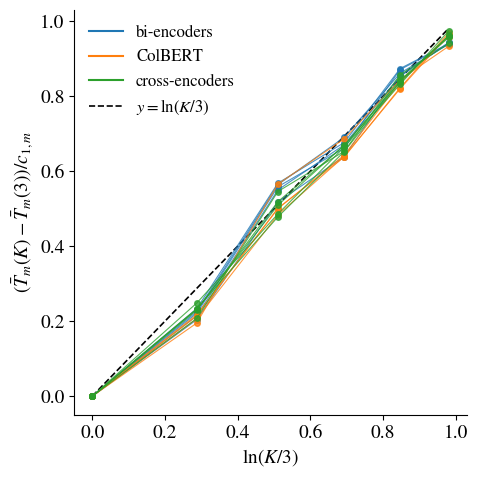

In [26]:
rescale_fit_k = [3, 4, 5, 6, 7, 8]
x = np.log(np.array(rescale_fit_k) / 3)                  # ln(K/3)

family_colors = {"bi-encoder": "tab:blue", "colbert": "tab:orange", "cross-encoder": "tab:green"}

fig, ax = plt.subplots(figsize=(5, 5))

for model in rescaled.index:
    color = family_colors[model.split("_")[0]]
    ax.plot(x, rescaled.loc[model, rescale_fit_k], "o-", ms=4, lw=0.8, alpha=0.8, color=color)

ax.plot(x, x, "k--", lw=1.2, zorder=0)                   # target y = ln(K/3)

ax.set_xlabel(r"$\ln(K/3)$")
ax.set_ylabel(r"$(\bar{T}_m(K)-\bar{T}_m(3))/c_{1,m}$")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.legend(handles=[
    Line2D([], [], color="tab:blue",   lw=1.5, label="bi-encoders"),
    Line2D([], [], color="tab:orange", lw=1.5, label="ColBERT"),
    Line2D([], [], color="tab:green",  lw=1.5, label="cross-encoders"),
    Line2D([], [], ls="--", color="black", lw=1.2, label=r"$y=\ln(K/3)$"),
], frameon=False, loc="upper left")

plt.tight_layout()
fig.savefig("collapse_lnk.pdf", bbox_inches="tight")
plt.show()

In [8]:
old_table = pd.read_csv("average_cutoffs_8.csv")

old_fit_table = old_table.set_index("model").drop(columns="percentile")
old_fit_table.columns = old_fit_table.columns.astype(int)
old_fit_table

,3,4,5,6,7,8
model,,,,,,
bi-encoder_BAAI-bge-large-en-v1.5.csv,0.061609,0.064933,0.071063,0.073761,0.075758,0.076381
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,0.104772,0.111568,0.120244,0.123677,0.127373,0.129968
bi-encoder_Qwen-Qwen3-Embedding-4B.csv,0.094074,0.102701,0.114553,0.119332,0.127957,0.129950
bi-encoder_Qwen-Qwen3-Embedding-8B.csv,0.089237,0.097338,0.108694,0.112027,0.117252,0.120252
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,0.095763,0.102555,0.112373,0.116323,0.122901,0.128221
colbert_LiquidAI-LFM2-ColBERT-350M.csv,0.000984,0.001112,0.001261,0.001332,0.001454,0.001490
colbert_colbert-ir-colbertv2.0.csv,0.062483,0.067846,0.076934,0.080269,0.083726,0.083598
colbert_lightonai-Reason-ModernColBERT.csv,0.024361,0.027357,0.031380,0.032896,0.035431,0.037408
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,0.100558,0.104932,0.113966,0.116281,0.120428,0.119298


In [9]:
old_train_k   = np.array([3, 4, 5, 6, 7, 8])
old_predict_k = np.array([10, 12, 14])
old_all_k     = np.concatenate([old_train_k, old_predict_k])


old_rows = []
for old_model, old_row in old_fit_table.iterrows():

    old_c0, old_c1 = fit_log(old_train_k, old_row[old_train_k].values)

    for k in old_all_k:
        old_pred = predict_log(old_c0, old_c1, k)
        old_act  = old_row[k] if k in old_train_k else np.nan    # no real value beyond K=8
        old_rows.append({"model": old_model, "k": k,
                         "split": "train" if k in old_train_k else "predict",
                         "c0": old_c0, "c1": old_c1,
                         "actual_p90": old_act,
                         "log_pred": old_pred,
                         "error": old_pred - old_act,
                         "abs_%_error": 100 * abs(old_pred - old_act) / old_act})

old_comparison = pd.DataFrame(old_rows)
display(old_comparison.round(5))

,model,k,split,c0,c1,actual_p90,log_pred,error,abs_%_error
0,bi-encoder_BAAI-bge-large-en-v1.5.csv,3,train,0.04362,0.01632,0.06161,0.06155,-0.00005,0.08907
1,bi-encoder_BAAI-bge-large-en-v1.5.csv,4,train,0.04362,0.01632,0.06493,0.06625,0.00132,2.02673
2,bi-encoder_BAAI-bge-large-en-v1.5.csv,5,train,0.04362,0.01632,0.07106,0.06989,-0.00117,1.64914
3,bi-encoder_BAAI-bge-large-en-v1.5.csv,6,train,0.04362,0.01632,0.07376,0.07287,-0.00089,1.21291
4,bi-encoder_BAAI-bge-large-en-v1.5.csv,7,train,0.04362,0.01632,0.07576,0.07538,-0.00038,0.49606
5,bi-encoder_BAAI-bge-large-en-v1.5.csv,8,train,0.04362,0.01632,0.07638,0.07756,0.00118,1.54653
6,bi-encoder_BAAI-bge-large-en-v1.5.csv,10,predict,0.04362,0.01632,NaN,0.08120,NaN,NaN
7,bi-encoder_BAAI-bge-large-en-v1.5.csv,12,predict,0.04362,0.01632,NaN,0.08418,NaN,NaN
8,bi-encoder_BAAI-bge-large-en-v1.5.csv,14,predict,0.04362,0.01632,NaN,0.08670,NaN,NaN
9,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,3,train,0.07603,0.02637,0.10477,0.10501,0.00024,0.22510


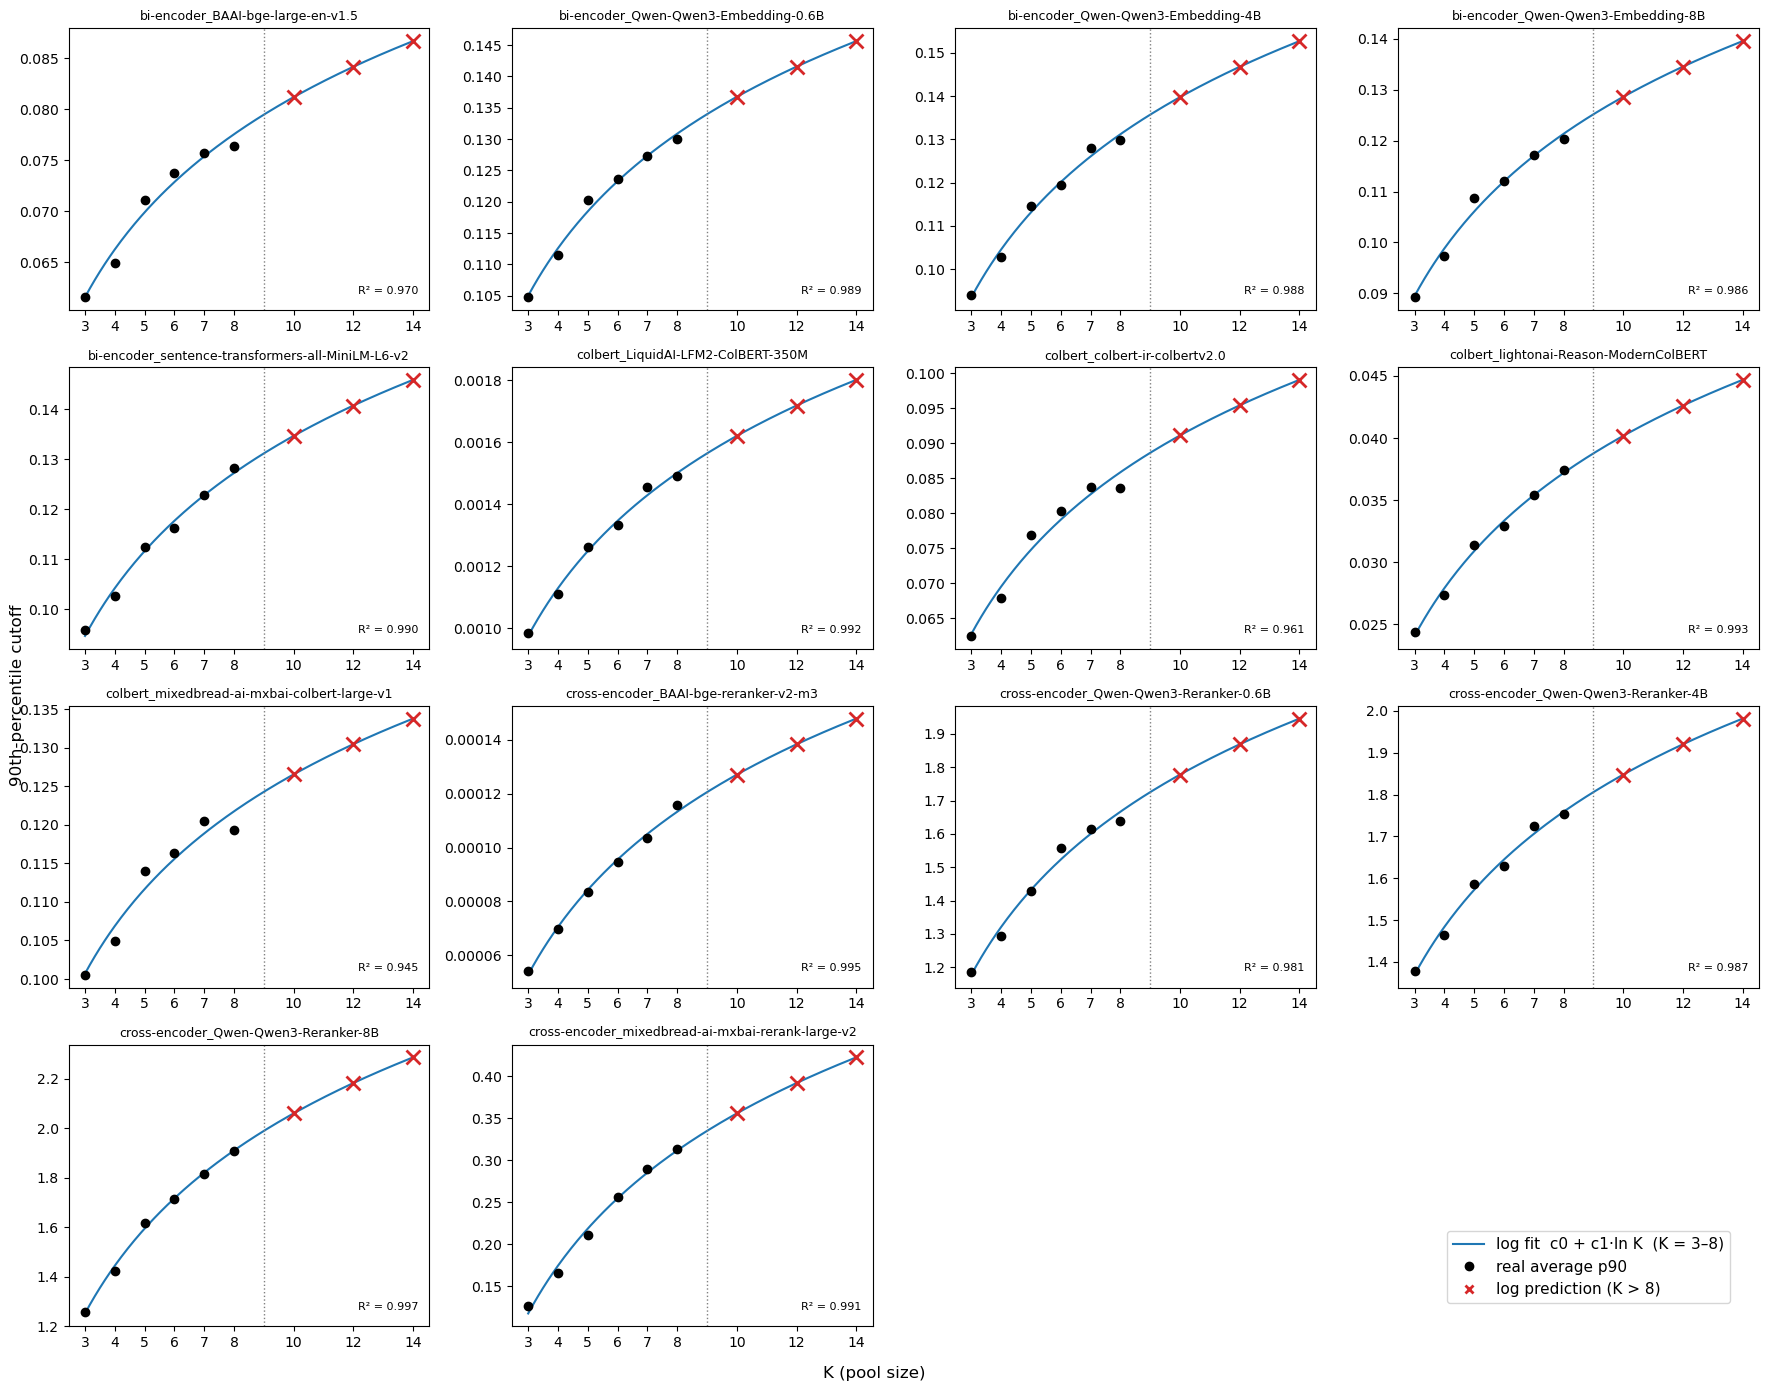

In [10]:
old_models  = old_comparison["model"].unique()
old_k_curve = np.linspace(3, 14, 200)

old_fig, old_axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, model in zip(old_axes.flat, old_models):
    d       = old_comparison[old_comparison["model"] == model]
    train   = d[d["split"] == "train"]
    predict = d[d["split"] == "predict"]
    c0, c1  = d["c0"].iloc[0], d["c1"].iloc[0]

    # R² of the fit on the training points
    y   = train["actual_p90"].values
    r2  = 1 - ((y - train["log_pred"].values) ** 2).sum() / ((y - y.mean()) ** 2).sum()

    # fitted curve
    ax.plot(old_k_curve, predict_log(c0, c1, old_k_curve), color="tab:blue", lw=1.5)
    # real averages (K = 3–8)
    ax.plot(train["k"], train["actual_p90"], "o", color="black")
    # predictions beyond the data
    ax.plot(predict["k"], predict["log_pred"], "x", color="tab:red", ms=10, mew=2)

    ax.axvline(9, color="grey", ls=":", lw=1)            # real data | prediction
    ax.set_title(model.replace(".csv", ""), fontsize=9)
    ax.set_xticks(sorted(d["k"].unique()))
    ax.text(0.97, 0.05, f"R² = {r2:.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=8)

for ax in old_axes.flat[len(old_models):]:
    ax.axis("off")

old_fig.legend(handles=[
    Line2D([], [], color="tab:blue", label="log fit  c0 + c1·ln K  (K = 3–8)"),
    Line2D([], [], marker="o", ls="", color="black", label="real average p90"),
    Line2D([], [], marker="x", ls="", color="tab:red", mew=2, label="log prediction (K > 8)"),
], loc="lower right", bbox_to_anchor=(0.98, 0.06), fontsize=11)

old_fig.supxlabel("K (pool size)")
old_fig.supylabel("90th-percentile cutoff")
plt.tight_layout()
plt.show()

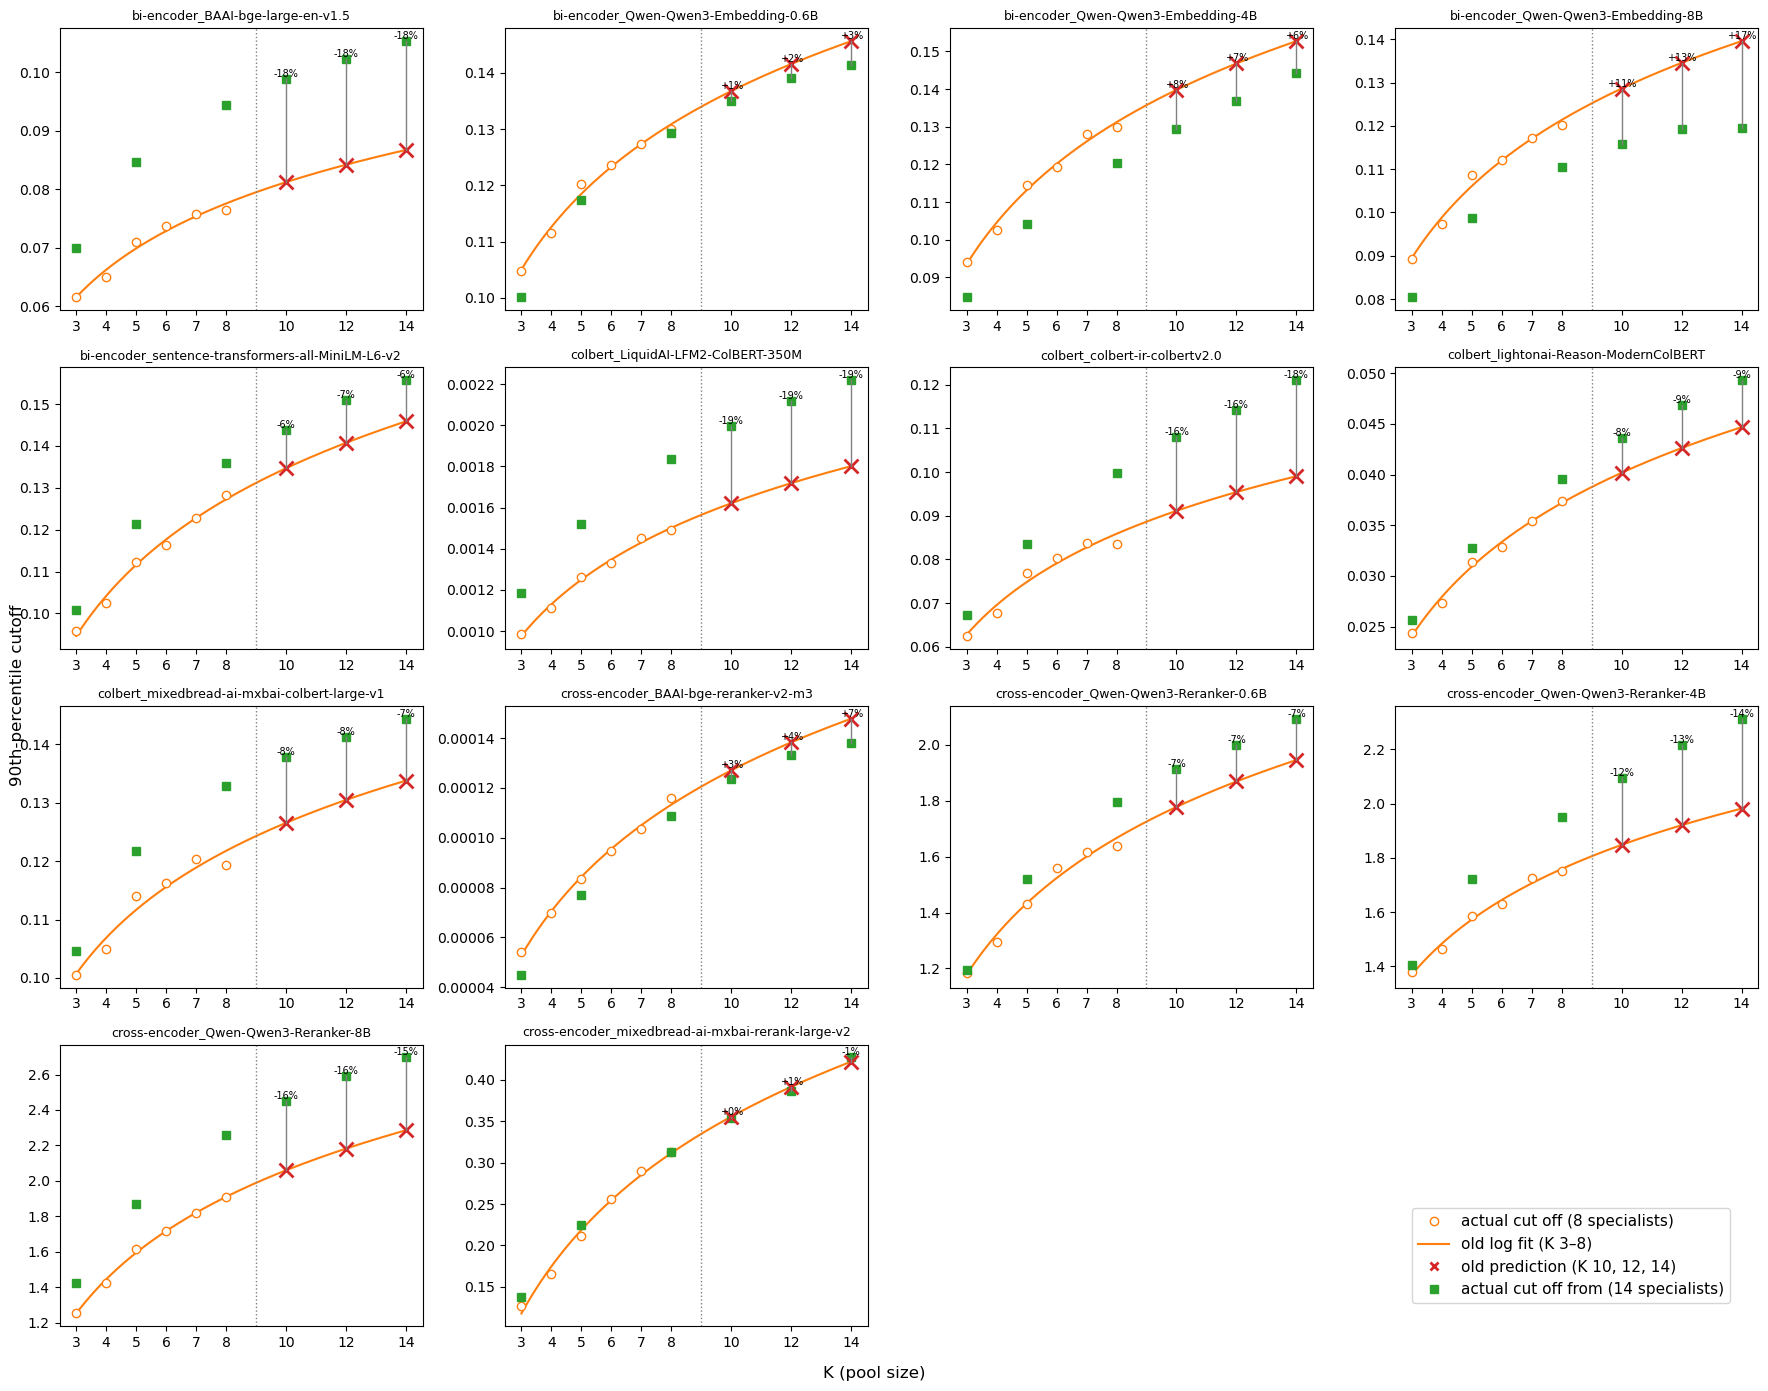

In [11]:
both_models = comparison["model"].unique()
both_k_curve = np.linspace(3, 14, 200)

both_fig, both_axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, model in zip(both_axes.flat, both_models):
    new = comparison[comparison["model"] == model].set_index("k")
    old = old_comparison[old_comparison["model"] == model].set_index("k")
    old_c0, old_c1 = old["c0"].iloc[0], old["c1"].iloc[0]

    # old data: real points (3–8) and its curve extended to 14
    ax.plot(both_k_curve, predict_log(old_c0, old_c1, both_k_curve),
            color="tab:orange", lw=1.5)
    old_real = old[old["split"] == "train"]
    ax.plot(old_real.index, old_real["actual_p90"], "o", color="tab:orange", mfc="white")

    # new data: real points at every K
    ax.plot(new.index, new["actual_p90"], "s", color="tab:green", ms=6)

    # old predictions at 10, 12, 14
    old_pred = old.loc[[10, 12, 14], "log_pred"]
    ax.plot(old_pred.index, old_pred.values, "x", color="tab:red", ms=10, mew=2)

    # vertical line + % difference at each predicted K
    for k in [10, 12, 14]:
        new_val, old_val = new.loc[k, "actual_p90"], old.loc[k, "log_pred"]
        ax.plot([k, k], [new_val, old_val], color="grey", lw=1)
        diff = 100 * (old_val - new_val) / new_val
        ax.text(k, max(new_val, old_val), f"{diff:+.0f}%",
                ha="center", va="bottom", fontsize=7)

    ax.axvline(9, color="grey", ls=":", lw=1)
    ax.set_title(model.replace(".csv", ""), fontsize=9)
    ax.set_xticks([3, 4, 5, 6, 7, 8, 10, 12, 14])

for ax in both_axes.flat[len(both_models):]:
    ax.axis("off")

both_fig.legend(handles=[
    Line2D([], [], marker="o", ls="", color="tab:orange", mfc="white", label="actual cut off (8 specialists)"),
    Line2D([], [], color="tab:orange", label="old log fit (K 3–8)"),
    Line2D([], [], marker="x", ls="", color="tab:red", mew=2, label="old prediction (K 10, 12, 14)"),
    Line2D([], [], marker="s", ls="", color="tab:green", label="actual cut off from (14 specialists)"),
], loc="lower right", bbox_to_anchor=(0.98, 0.06), fontsize=11)

both_fig.supxlabel("K (pool size)")
both_fig.supylabel("90th-percentile cutoff")
plt.tight_layout()
plt.show()

In [12]:
compare_k = [10, 12, 14]

new_real = comparison[comparison["k"].isin(compare_k)][["model", "k", "actual_p90"]]
old_pred = old_comparison[old_comparison["k"].isin(compare_k)][["model", "k", "log_pred"]]

result = new_real.merge(old_pred, on=["model", "k"])
result["diff_%"] = 100 * (result["log_pred"] - result["actual_p90"]) / result["actual_p90"]

display(result.round(5))

,model,k,actual_p90,log_pred,diff_%
0,bi-encoder_BAAI-bge-large-en-v1.5.csv,10,0.09885,0.08120,-17.84758
1,bi-encoder_BAAI-bge-large-en-v1.5.csv,12,0.10221,0.08418,-17.64258
2,bi-encoder_BAAI-bge-large-en-v1.5.csv,14,0.10527,0.08670,-17.64802
3,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,10,0.13493,0.13676,1.35768
4,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,12,0.13912,0.14157,1.75958
5,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,14,0.14130,0.14563,3.06526
6,bi-encoder_Qwen-Qwen3-Embedding-4B.csv,10,0.12928,0.13979,8.13040
7,bi-encoder_Qwen-Qwen3-Embedding-4B.csv,12,0.13686,0.14681,7.26576
8,bi-encoder_Qwen-Qwen3-Embedding-4B.csv,14,0.14426,0.15274,5.88044
9,bi-encoder_Qwen-Qwen3-Embedding-8B.csv,10,0.11589,0.12863,10.99706


In [14]:
# from the 14-specialist table: model, K, real cutoff
new_part = comparison[["model", "k", "actual_p90"]].rename(
    columns={"actual_p90": "actual_14_specialists"})

# from the 8-specialist table: model, K, real cutoff, prediction, c0, c1
old_part = old_comparison[["model", "k", "actual_p90", "log_pred", "c0", "c1"]].rename(
    columns={"actual_p90": "actual_8_specialists",
             "log_pred":   "predicted_8_specialists",
             "c0":         "c0_8_specialists",
             "c1":         "c1_8_specialists"})

# put them together: one row per model and K
plot_table = new_part.merge(old_part, on=["model", "k"], how="outer").sort_values(["model", "k"])
display(plot_table.round(5))

,model,k,actual_14_specialists,actual_8_specialists,predicted_8_specialists,c0_8_specialists,c1_8_specialists
0,bi-encoder_BAAI-bge-large-en-v1.5.csv,3,0.07002,0.06161,0.06155,0.04362,0.01632
84,bi-encoder_BAAI-bge-large-en-v1.5.csv,4,NaN,0.06493,0.06625,0.04362,0.01632
1,bi-encoder_BAAI-bge-large-en-v1.5.csv,5,0.08460,0.07106,0.06989,0.04362,0.01632
85,bi-encoder_BAAI-bge-large-en-v1.5.csv,6,NaN,0.07376,0.07287,0.04362,0.01632
86,bi-encoder_BAAI-bge-large-en-v1.5.csv,7,NaN,0.07576,0.07538,0.04362,0.01632
2,bi-encoder_BAAI-bge-large-en-v1.5.csv,8,0.09430,0.07638,0.07756,0.04362,0.01632
3,bi-encoder_BAAI-bge-large-en-v1.5.csv,10,0.09885,NaN,0.08120,0.04362,0.01632
4,bi-encoder_BAAI-bge-large-en-v1.5.csv,12,0.10221,NaN,0.08418,0.04362,0.01632
5,bi-encoder_BAAI-bge-large-en-v1.5.csv,14,0.10527,NaN,0.08670,0.04362,0.01632
6,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,3,0.10010,0.10477,0.10501,0.07603,0.02637


In [73]:
# train_k = np.array([3, 4, 5, 6, 7, 8])
# test_k  = np.array([12, 14])
# all_k   = np.concatenate([train_k, test_k])

# def fit_log(k, y):
#     b, a = np.polyfit(np.log(k), y, 1)   # y = a + b*ln(k)
#     return a, b

# def predict_log(a, b, k):
#     return a + b * np.log(k)

# results = {}
# rows = []

# for file_name, scores in score_tables.items():
#     actual = average_cutoffs(scores, all_k, number_of_specialists, show=False)
#     actual_train = actual[:len(train_k)]
#     actual_test  = actual[len(train_k):]

#     a, b = fit_log(train_k, actual_train)
#     pred_test = predict_log(a, b, test_k)

#     results[file_name] = dict(actual=actual, a=a, b=b)

#     for k, act, pred in zip(test_k, actual_test, pred_test):
#         rows.append({
#             "model": file_name.replace(".csv", ""),
#             "k": k,
#             "actual_p90": act,
#             "log_pred": pred,
#             "error": pred - act,
#             "abs_%_error": 100 * abs(pred - act) / act,
#         })

# comparison = pd.DataFrame(rows).round(5)
# comparison

In [74]:
# k_curve = np.linspace(3, 14, 100)

# fig, axes = plt.subplots(4, 4, figsize=(18, 14), sharex=True)
# for ax, (file_name, r) in zip(axes.flat, results.items()):
#     n = len(train_k)
#     ax.plot(train_k, r["actual"][:n], "o", color="black")
#     ax.plot(test_k,  r["actual"][n:], "s", color="tab:green")
#     ax.plot(k_curve, predict_log(r["a"], r["b"], k_curve), "-", color="tab:blue")
#     ax.plot(test_k, predict_log(r["a"], r["b"], test_k), "x", color="tab:red", ms=9)
#     ax.set_title(file_name.replace(".csv", ""), fontsize=8)
# for ax in axes.flat[len(results):]:
#     ax.axis("off")

# fig.legend(handles=[
#     Line2D([], [], marker="o", ls="", color="black", label="train actual (k=3,5,8,10)"),
#     Line2D([], [], marker="s", ls="", color="tab:green", label="test actual (k=12,14)"),
#     Line2D([], [], color="tab:blue", label="log fit"),
#     Line2D([], [], marker="x", ls="", color="tab:red", label="log prediction (k=12,14)"),
# ], loc="lower right")
# fig.supxlabel("k (pool size)"); fig.supylabel("average 90th-pct cutoff")
# plt.tight_layout(); plt.show()

In [21]:
old_table = pd.read_csv("average_cutoffs_8.csv")
old_fit_table = old_table.set_index("model").drop(columns="percentile")
old_fit_table

,3,4,5,6,7,8
model,,,,,,
bi-encoder_BAAI-bge-large-en-v1.5.csv,0.061609,0.064933,0.071063,0.073761,0.075758,0.076381
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,0.104772,0.111568,0.120244,0.123677,0.127373,0.129968
bi-encoder_Qwen-Qwen3-Embedding-4B.csv,0.094074,0.102701,0.114553,0.119332,0.127957,0.129950
bi-encoder_Qwen-Qwen3-Embedding-8B.csv,0.089237,0.097338,0.108694,0.112027,0.117252,0.120252
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,0.095763,0.102555,0.112373,0.116323,0.122901,0.128221
colbert_LiquidAI-LFM2-ColBERT-350M.csv,0.000984,0.001112,0.001261,0.001332,0.001454,0.001490
colbert_colbert-ir-colbertv2.0.csv,0.062483,0.067846,0.076934,0.080269,0.083726,0.083598
colbert_lightonai-Reason-ModernColBERT.csv,0.024361,0.027357,0.031380,0.032896,0.035431,0.037408
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,0.100558,0.104932,0.113966,0.116281,0.120428,0.119298


In [34]:
log_constants = {}

for model in old_fit_table.index:
    cutoffs = old_fit_table.loc[model].values 
    c1, c0  = np.polyfit(np.log(fit_k), cutoffs, 1)
    log_constants[model] = (c0, c1)
    print(f"{model:55s} c0 = {c0:.5f}  c1 = {c1:.5f}")
    
    
# log_constants

bi-encoder_BAAI-bge-large-en-v1.5.csv                   c0 = 0.04362  c1 = 0.01632
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv                c0 = 0.07603  c1 = 0.02637
bi-encoder_Qwen-Qwen3-Embedding-4B.csv                  c0 = 0.05121  c1 = 0.03847
bi-encoder_Qwen-Qwen3-Embedding-8B.csv                  c0 = 0.05373  c1 = 0.03253
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv   c0 = 0.05801  c1 = 0.03330
colbert_LiquidAI-LFM2-ColBERT-350M.csv                  c0 = 0.00039  c1 = 0.00054
colbert_colbert-ir-colbertv2.0.csv                      c0 = 0.03689  c1 = 0.02356
colbert_lightonai-Reason-ModernColBERT.csv              c0 = 0.00936  c1 = 0.01339
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv        c0 = 0.07712  c1 = 0.02146
cross-encoder_BAAI-bge-reranker-v2-m3.csv               c0 = -0.00001  c1 = 0.00006
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv              c0 = 0.62962  c1 = 0.49870
cross-encoder_Qwen-Qwen3-Reranker-4B.csv                c0 = 0.93325  c1 = 0.39715
cro

In [35]:
predict_these_k = [3, 5, 8, 10, 12, 14]

predicted_rows = {}
for model in log_constants:
    c0, c1 = log_constants[model]
    predicted_rows[model] = [c0 + c1 * np.log(k) for k in predict_these_k]

predicted_table = pd.DataFrame(predicted_rows, index=predict_these_k).T
predicted_table.columns.name = "K"
predicted_table.round(5)

K,3,5,8,10,12,14
bi-encoder_BAAI-bge-large-en-v1.5.csv,0.06155,0.06989,0.07756,0.08120,0.08418,0.08670
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,0.10501,0.11848,0.13088,0.13676,0.14157,0.14563
bi-encoder_Qwen-Qwen3-Embedding-4B.csv,0.09348,0.11313,0.13121,0.13979,0.14681,0.15274
bi-encoder_Qwen-Qwen3-Embedding-8B.csv,0.08947,0.10609,0.12137,0.12863,0.13456,0.13958
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,0.09460,0.11161,0.12726,0.13469,0.14076,0.14590
colbert_LiquidAI-LFM2-ColBERT-350M.csv,0.00098,0.00125,0.00150,0.00162,0.00172,0.00180
colbert_colbert-ir-colbertv2.0.csv,0.06277,0.07481,0.08588,0.09114,0.09544,0.09907
colbert_lightonai-Reason-ModernColBERT.csv,0.02407,0.03090,0.03720,0.04018,0.04262,0.04469
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,0.10070,0.11167,0.12175,0.12654,0.13046,0.13376
cross-encoder_BAAI-bge-reranker-v2-m3.csv,0.00005,0.00008,0.00011,0.00013,0.00014,0.00015


In [40]:
difference_table = predicted_table - real_table
difference_table.round(5)

K,3,5,8,10,12,14
bi-encoder_BAAI-bge-large-en-v1.5.csv,-0.00846,-0.01471,-0.01673,-0.01764,-0.01803,-0.01858
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,0.00491,0.00102,0.00162,0.00183,0.00245,0.00433
bi-encoder_Qwen-Qwen3-Embedding-4B.csv,0.00874,0.00885,0.01087,0.01051,0.00994,0.00848
bi-encoder_Qwen-Qwen3-Embedding-8B.csv,0.00905,0.00743,0.01078,0.01274,0.01518,0.02006
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,-0.00619,-0.00972,-0.00869,-0.00911,-0.01024,-0.00990
colbert_LiquidAI-LFM2-ColBERT-350M.csv,-0.00021,-0.00027,-0.00033,-0.00038,-0.00040,-0.00042
colbert_colbert-ir-colbertv2.0.csv,-0.00443,-0.00875,-0.01393,-0.01690,-0.01870,-0.02206
colbert_lightonai-Reason-ModernColBERT.csv,-0.00153,-0.00190,-0.00232,-0.00347,-0.00421,-0.00467
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,-0.00389,-0.01006,-0.01111,-0.01121,-0.01078,-0.01059
cross-encoder_BAAI-bge-reranker-v2-m3.csv,0.00001,0.00001,0.00000,0.00000,0.00001,0.00001


In [41]:
side_by_side = pd.concat({"Real": real_table, "Predicted": predicted_table, "Difference": difference_table}, axis=1)
side_by_side = side_by_side.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
side_by_side.round(5)

K                                                           3             \
                                                          Real Predicted   
bi-encoder_BAAI-bge-large-en-v1.5.csv                  0.07002   0.06155   
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv               0.10010   0.10501   
bi-encoder_Qwen-Qwen3-Embedding-4B.csv                 0.08474   0.09348   
bi-encoder_Qwen-Qwen3-Embedding-8B.csv                 0.08042   0.08947   
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv  0.10079   0.09460   
colbert_LiquidAI-LFM2-ColBERT-350M.csv                 0.00118   0.00098   
colbert_colbert-ir-colbertv2.0.csv                     0.06720   0.06277   
colbert_lightonai-Reason-ModernColBERT.csv             0.02560   0.02407   
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv       0.10459   0.10070   
cross-encoder_BAAI-bge-reranker-v2-m3.csv              0.00005   0.00005   
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv             1.19413   1.17750   
cross-encoder_Qwen-Qwen3-Reranker-4B.csv               1.40632   1.36956   
cross-encoder_Qwen-Qwen3-Reranker-8B.csv               1.42611   1.25159   
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv  0.13808   0.11773   

K                                                                      5   \
                                                      Difference     Real   
bi-encoder_BAAI-bge-large-en-v1.5.csv                   -0.00846  0.08460   
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv                 0.00491  0.11746   
bi-encoder_Qwen-Qwen3-Embedding-4B.csv                   0.00874  0.10428   
bi-encoder_Qwen-Qwen3-Embedding-8B.csv                   0.00905  0.09865   
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv   -0.00619  0.12133   
colbert_LiquidAI-LFM2-ColBERT-350M.csv                  -0.00021  0.00152   
colbert_colbert-ir-colbertv2.0.csv                      -0.00443  0.08356   
colbert_lightonai-Reason-ModernColBERT.csv              -0.00153  0.03280   
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv        -0.00389  0.12173   
cross-encoder_BAAI-bge-reranker-v2-m3.csv                0.00001  0.00008   
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv              -0.01663  1.52003   
cross-encoder_Qwen-Qwen3-Reranker-4B.csv                -0.03676  1.72098   
cross-encoder_Qwen-Qwen3-Reranker-8B.csv                -0.17451  1.86869   
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv   -0.02035  0.22487   

K                                                                           \
                                                      Predicted Difference   
bi-encoder_BAAI-bge-large-en-v1.5.csv                   0.06989   -0.01471   
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv                0.11848    0.00102   
bi-encoder_Qwen-Qwen3-Embedding-4B.csv                  0.11313    0.00885   
bi-encoder_Qwen-Qwen3-Embedding-8B.csv                  0.10609    0.00743   
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv   0.11161   -0.00972   
colbert_LiquidAI-LFM2-ColBERT-350M.csv                  0.00125   -0.00027   
colbert_colbert-ir-colbertv2.0.csv                      0.07481   -0.00875   
colbert_lightonai-Reason-ModernColBERT.csv              0.03090   -0.00190   
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv        0.11167   -0.01006   
cross-encoder_BAAI-bge-reranker-v2-m3.csv               0.00008    0.00001   
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv              1.43224   -0.08778   
cross-encoder_Qwen-Qwen3-Reranker-4B.csv                1.57243   -0.14855   
cross-encoder_Qwen-Qwen3-Reranker-8B.csv                1.59451   -0.27417   
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv   0.21868   -0.00619   

K                                                           8             \
                                                          Real Predicted   
bi-encoder_BAAI-bge-large-en-v1.5.csv                  0.09430   0.07756   
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv               0.12926   0.13088 

In [44]:
# model = "bi-encoder_BAAI-bge-large-en-v1.5.csv"

# # Real: the dots
# x_real = real_table.columns            # K = 3, 5, 8, 10, 12, 14
# y_real = real_table.loc[model]         # real threshold at each K

# # Predicted: the line
# c0, c1 = log_constants[model]
# x_pred = np.linspace(3, 14, 100)       # K from 3 to 14
# y_pred = c0 + c1 * np.log(x_pred)      # predicted threshold at each K

# print("x_real:", list(x_real))
# print("y_real:", np.round(y_real.values, 5))

x_real: [3, 5, 8, 10, 12, 14]
y_real: [0.07002 0.0846  0.0943  0.09885 0.10221 0.10527]


In [48]:
# plt.plot(x_pred, y_pred, label="Predicted (log)")
# plt.plot(x_real, y_real, "o", label="Real")

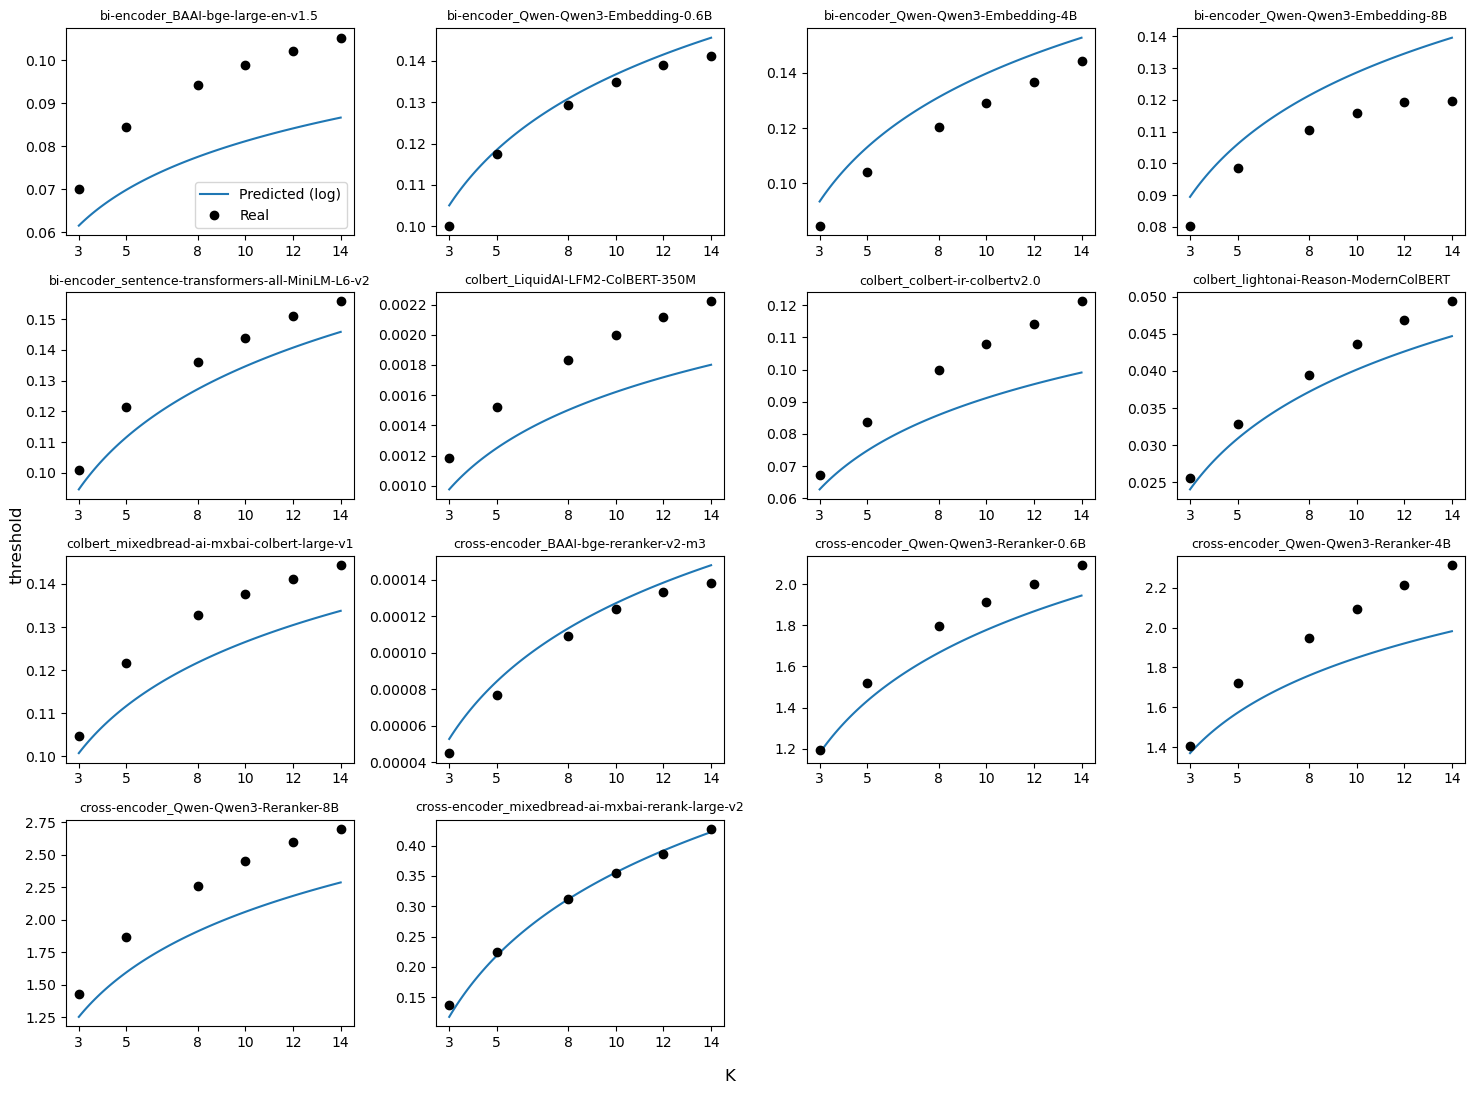

In [49]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
axes = axes.flatten()

for ax, model in zip(axes, real_table.index):

    # Real: the dots
    x_real = real_table.columns
    y_real = real_table.loc[model]

    # Predicted: the line
    c0, c1 = log_constants[model]
    x_pred = np.linspace(3, 14, 100)
    y_pred = c0 + c1 * np.log(x_pred)

    ax.plot(x_pred, y_pred, label="Predicted (log)")
    ax.plot(x_real, y_real, "o", color="black", label="Real")
    ax.set_title(model.replace(".csv", ""), fontsize=9)
    ax.set_xticks([3, 5, 8, 10, 12, 14])

# hide the 2 empty panels (16 panels, 14 models)
for ax in axes[len(real_table):]:
    ax.set_visible(False)

axes[0].legend()
fig.supxlabel("K")
fig.supylabel("threshold")
fig.tight_layout()
fig.savefig("real_vs_predicted_14_models.pdf")
plt.show()
